# GOAL: Pixel-level masks on satellite pictures of houses

- Use the pixel-level results from the SAM model (lots of overlapping predictions) by checking which ones "agree" with the satellite-building-segmentation labels.
- "Agree" means a high Jaccard index (IoU, intersection over union) between a SAM mask and a labelled building box.

**Runs on a CPU** in the course container (`pytorch` image), in a few minutes. It needs the network: it downloads three labelled images (the dataset's `mini` split, about 150 KB) and the smallest SAM model, ViT-B (375 MB).
On a GPU (in Colab: Runtime, Change runtime type, T4 GPU) it uses the largest model, ViT-H (2.5 GB), as the original notebook did.

Outside the course container: `pip install torch torchvision datasets segment-anything matplotlib`.

In [1]:
import os

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import torch

# COURSE_SMOKE=1 (the course smoke test) asks SAM for fewer masks, so the run is shorter
SMOKE = os.environ.get("COURSE_SMOKE") == "1"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cpu


**Load the satellite dataset**

In [2]:
from datasets import load_dataset

# From https://huggingface.co/datasets/keremberke/satellite-building-segmentation
# The dataset's own loading script no longer runs (datasets 4 and later), so read the
# Parquet copy that Hugging Face keeps of it: the "mini" split has three 500x500 images.
PARQUET = "hf://datasets/keremberke/satellite-building-segmentation@refs%2Fconvert%2Fparquet/"
ds = load_dataset("parquet", data_files={"train": PARQUET + "mini/train/0000.parquet"})
example = ds["train"][0]
print(example.keys())
example["objects"]["bbox"]

dict_keys(['image_id', 'image', 'width', 'height', 'objects'])


[[366.0, 280.0, 76.25, 42.220001220703125],
 [261.0, 193.0, 54.0, 59.560001373291016],
 [316.0, 335.0, 92.19000244140625, 165.13999938964844],
 [366.0, 207.0, 42.0, 58.09000015258789],
 [464.0, 0.0, 36.04999923706055, 18.420000076293945],
 [55.0, 210.0, 114.2300033569336, 125.55000305175781]]

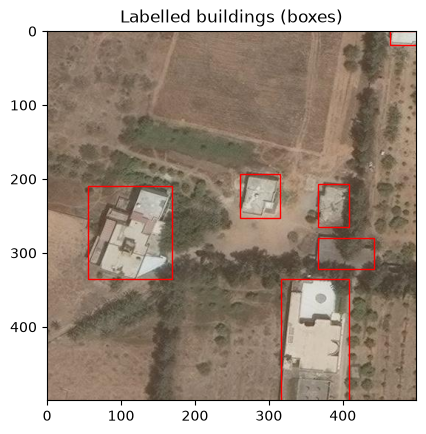

In [3]:
image = example["image"].convert("RGB")

fig, ax = plt.subplots(1)
ax.imshow(image)
ax.set_title("Labelled buildings (boxes)")

for bbox in example["objects"]["bbox"]:
    x_min, y_min, width, height = bbox
    rect = patches.Rectangle((x_min, y_min), width, height, linewidth=1, edgecolor='r', facecolor='none')
    ax.add_patch(rect)

plt.show()

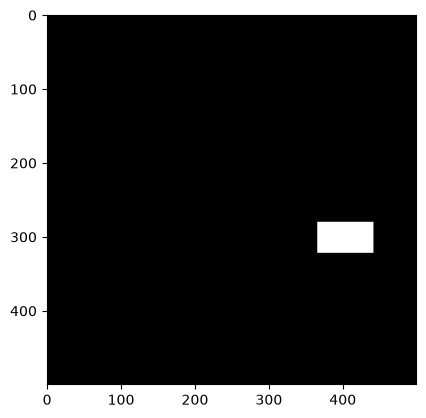

In [4]:
def make_mask(labelled_bbox, image):
    """A binary mask (rows = y, columns = x) that is 1 inside a labelled box."""
    x_min, y_min, width, height = (int(v) for v in labelled_bbox)
    mask = np.zeros((image.height, image.width))
    mask[y_min:y_min + height, x_min:x_min + width] = 1
    return mask


mask_instance = make_mask(example["objects"]["bbox"][0], image)
plt.imshow(mask_instance, cmap='gray')
plt.show()

**Load SAM (Segment Anything)**

The automatic mask generator prompts SAM with a grid of points over the image and keeps the good masks.

In [5]:
# From: https://github.com/facebookresearch/segment-anything/blob/main/notebooks/automatic_mask_generator_example.ipynb
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator

# ViT-H (2.5 GB) on a GPU; the smallest model, ViT-B (375 MB), on a CPU
if device == "cuda" and not SMOKE:
    model_type, sam_checkpoint = "vit_h", "sam_vit_h_4b8939.pth"
else:
    model_type, sam_checkpoint = "vit_b", "sam_vit_b_01ec64.pth"

if not os.path.exists(sam_checkpoint):
    torch.hub.download_url_to_file(
        "https://dl.fbaipublicfiles.com/segment_anything/" + sam_checkpoint, sam_checkpoint, progress=False)

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)

# A 32x32 grid of point prompts is SAM's default; 8x8 is enough for a smoke test
mask_generator = SamAutomaticMaskGenerator(sam, points_per_side=8 if SMOKE else 32)

In [6]:
def show_anns(anns):
    if len(anns) == 0:
        return
    sorted_anns = sorted(anns, key=(lambda x: x['area']), reverse=True)
    ax = plt.gca()
    ax.set_autoscale_on(False)
    img = np.ones((sorted_anns[0]['segmentation'].shape[0], sorted_anns[0]['segmentation'].shape[1], 4))
    img[:, :, 3] = 0
    for ann in sorted_anns:
        m = ann['segmentation']
        color_mask = np.concatenate([np.random.random(3), [0.35]])
        img[m] = color_mask
    ax.imshow(img)

In [7]:
masks = mask_generator.generate(np.array(image))
print(len(masks), "masks")
print(masks[0].keys())

52 masks
dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])


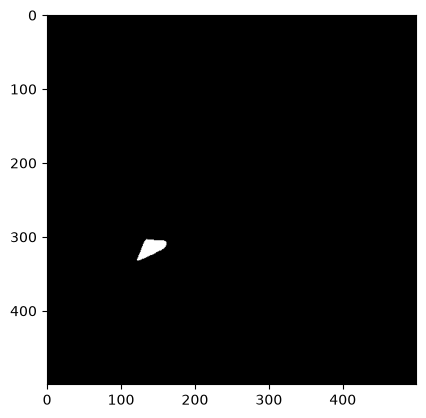

In [8]:
binary_array = masks[0]['segmentation'].astype(int)
plt.imshow(binary_array, cmap='gray')
plt.show()

In [9]:
for m in masks:
    print(m['bbox'])

[122.0, 303.0, 39.0, 29.0]
[202.0, 446.0, 20.0, 19.0]
[325.0, 271.0, 14.0, 14.0]
[401.0, 18.0, 23.0, 36.0]
[466.0, 0.0, 33.0, 16.0]
[363.0, 355.0, 15.0, 13.0]
[44.0, 152.0, 26.0, 23.0]
[342.0, 337.0, 48.0, 51.0]
[463.0, 251.0, 25.0, 17.0]
[406.0, 413.0, 17.0, 15.0]
[73.0, 155.0, 13.0, 16.0]
[406.0, 397.0, 17.0, 31.0]
[443.0, 254.0, 15.0, 19.0]
[452.0, 167.0, 20.0, 20.0]
[456.0, 97.0, 23.0, 53.0]
[447.0, 205.0, 22.0, 18.0]
[410.0, 360.0, 22.0, 31.0]
[410.0, 396.0, 15.0, 13.0]
[225.0, 394.0, 22.0, 32.0]
[466.0, 237.0, 13.0, 13.0]
[425.0, 470.0, 15.0, 14.0]
[85.0, 332.0, 18.0, 19.0]
[98.0, 279.0, 21.0, 21.0]
[73.0, 288.0, 23.0, 37.0]
[349.0, 242.0, 20.0, 17.0]
[423.0, 448.0, 21.0, 20.0]
[261.0, 191.0, 51.0, 57.0]
[51.0, 211.0, 12.0, 8.0]
[338.0, 470.0, 45.0, 29.0]
[425.0, 0.0, 37.0, 64.0]
[471.0, 205.0, 12.0, 10.0]
[153.0, 0.0, 18.0, 11.0]
[478.0, 285.0, 20.0, 30.0]
[430.0, 279.0, 21.0, 16.0]
[176.0, 189.0, 9.0, 9.0]
[330.0, 336.0, 15.0, 17.0]
[339.0, 274.0, 25.0, 28.0]
[94.0, 224.0, 16.0

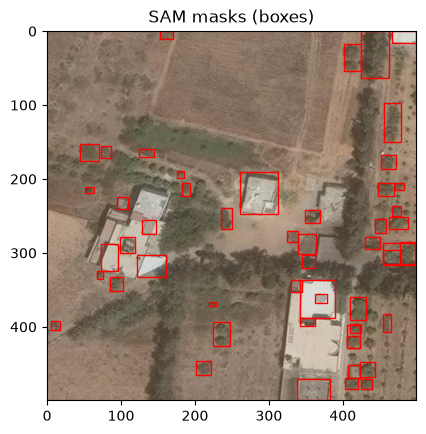

In [10]:
fig, ax = plt.subplots(1)
ax.imshow(image)
ax.set_title("SAM masks (boxes)")

for m in masks:
    x_min, y_min, width, height = m['bbox']
    rect = patches.Rectangle((x_min, y_min), width, height, linewidth=1, edgecolor='r', facecolor='none')
    ax.add_patch(rect)

plt.show()

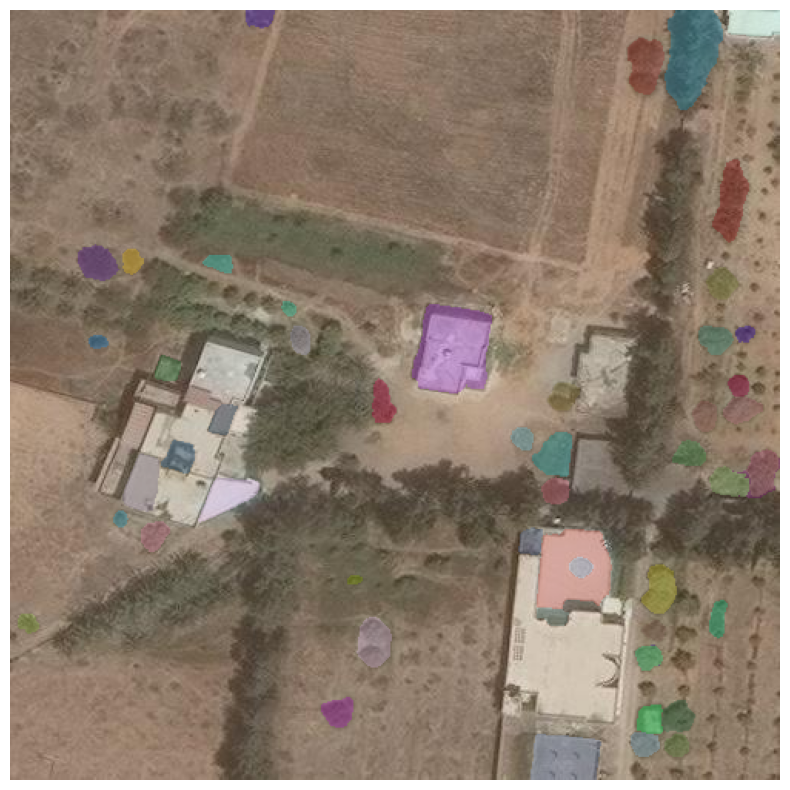

In [11]:
plt.figure(figsize=(10, 10))
plt.imshow(image)
show_anns(masks)
plt.axis('off')
plt.show()

**Which SAM masks agree with the labels?**

The Jaccard index (IoU) of two binary masks is the area of their intersection (logical AND) divided by the area of their union (logical OR).
Show every pair with an IoU above 0.3.

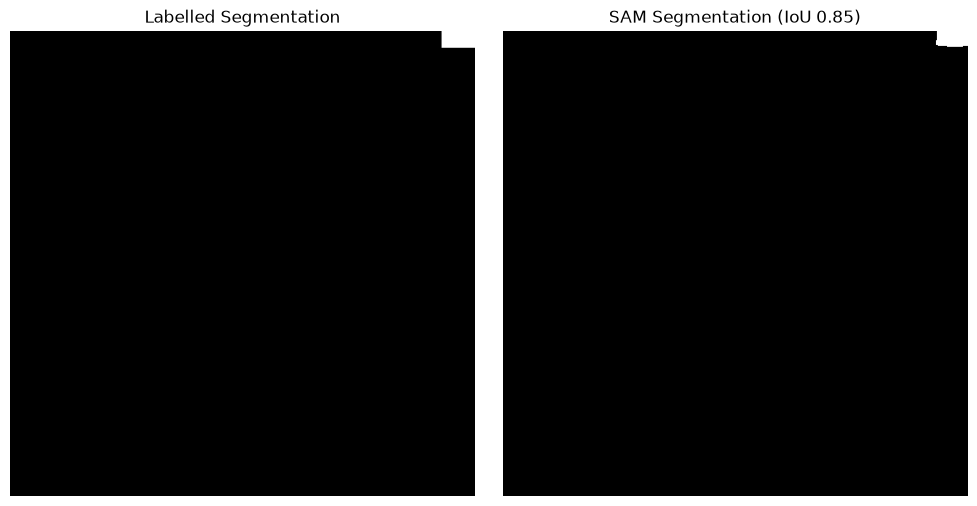

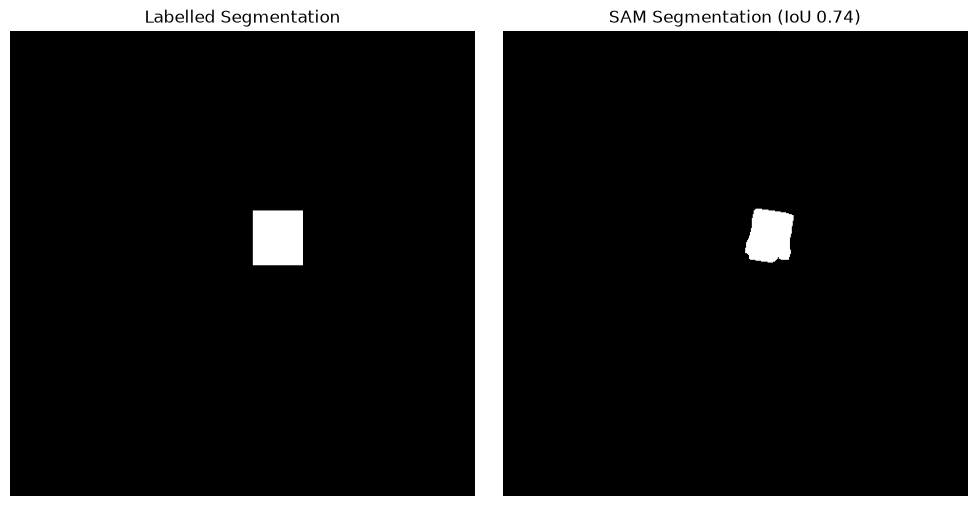

2 SAM masks match a labelled building with IoU > 0.3


In [12]:
def iou(mask_a, mask_b):
    return np.sum(np.logical_and(mask_a, mask_b)) / np.sum(np.logical_or(mask_a, mask_b))


matches = 0
for sam_box in masks:
    sam_seg = sam_box['segmentation'].astype(int)
    for label_box in example["objects"]["bbox"]:
        label_seg = make_mask(label_box, image)
        score = iou(sam_seg, label_seg)
        if score > 0.3:
            matches += 1
            fig, axes = plt.subplots(1, 2, figsize=(10, 5))
            axes[0].imshow(label_seg, cmap='gray')
            axes[0].set_title('Labelled Segmentation')
            axes[0].axis('off')
            axes[1].imshow(sam_seg, cmap='gray')
            axes[1].set_title(f'SAM Segmentation (IoU {score:.2f})')
            axes[1].axis('off')
            plt.tight_layout()
            plt.show()

print(f"{matches} SAM masks match a labelled building with IoU > 0.3")